In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'   # ajuste para o nº de núcleos do seu computador

# 05 — Modelagem (Fase 4): regressão, baselines e machine learning

Este notebook leva o projeto da exploração (Fase 3) para a **previsão**: dado o balanço de uma empresa **fora de distress em t**, qual a chance de ela entrar em distress em t+1 e t+2? A regressão logística é o modelo principal, comparada com a baseline (Z'' de Altman) e com dois desafiantes não lineares (gradient boosting e random forest). Como regressão de referência, a seção 5 também ajusta o modelo linear de probabilidade, com checagem de resíduos e multicolinearidade.

Regras que vêm dos notebooks anteriores e valem aqui:
- **O teste (t = 2021–2023) só é aberto na seção 7, uma vez**, depois de congelar modelo, variáveis, hiperparâmetros e limiar. Nada antes dela olha o teste.
- **Hiperparâmetros por validação temporal expandida dentro do treino** (notebook 04, "Riscos da escolha B"), com intervalo de 2 anos entre treino e validação, porque o alvo de t olha t+1 e t+2.
- **Nada que aprende dos dados é calculado fora do pipeline**: limites da winsorização, p99 do sem-dívida, medianas, média e desvio da padronização e coeficientes são ajustados só no treino de cada dobra (`src/modelagem.py`). Por isso aqui usamos as colunas cruas, e não as `*_w` da Fase 2.
- **Métrica principal: AUC-PR**, com AUC-ROC, Brier e recall no top 20% como apoio. Acurácia não entra: prever sempre "não" já acerta cerca de 90%.
- **Incerteza honesta**: os intervalos vêm de *bootstrap por empresa* (a mesma empresa aparece em vários anos), e a validação tem poucos eventos.

| decisão | valor aplicado aqui | situação |
|---|---|---|
| definição do alvo | `cfg.ALVO_MODELO` (B: EBITDA / desp. fin. < 1 em t+1 e t+2) | recomendação do notebook 04; **a escolha é da dupla** |
| empresas sem dívida | `fco_divida` = p99 do treino, `divida_cp_share` = 0, flag `sem_divida` | sugestão do notebook 03; **pendente** (comparada na seção 6) |
| controle de tempo | nenhum (risco relativo dentro de cada ano) | **pendente** (Selic/PIB: ver `cfg.MACRO_COLS`) |
| setor | macrossetor provisório da CVM | pendente: Subsetor Bovespa |
| divisão | treino 2010–2018, validação 2019–2020, teste 2021–2023 | decidida em 21/10/2026 |

Os **títulos dos gráficos estão neutros** de propósito: depois de ler o resultado, troque-os pela afirmação que ele sustenta (como nos notebooks 03 e 04).

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, modelagem as mod, avaliacao as av, style

style.aplicar()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: style.num_br(x, 3))

ea = mod.carregar_base()
amostra = mod.preparar_amostra(ea)   # alvo cfg.ALVO_MODELO; amostra em risco, t de 2010 a 2023
print(f'Alvo {cfg.ALVO_MODELO}:', cfg.DEFINICOES_ALVO[cfg.ALVO_MODELO], '| base:', ea.shape, '| amostra em risco:', len(amostra))

Alvo B: ('ebitda', 2) | base: (3633, 58) | amostra em risco: 1845


## 1. Amostra e divisão temporal

A amostra é a mesma do notebook 04 para a definição escolhida: empresas **fora de distress em t** (pela mesma definição), com Y observado, sem anos anteriores ao registro na CVM e com t até 2023.

O critério 3 do notebook 04 (idealmente 10 eventos por parâmetro) não é atingido por nenhuma definição, e a B fica em cerca de 6. Por isso a logística usa **regularização L2** (seção 3).

In [3]:
resumo = mod.resumo_amostra(amostra)
esperado = {'A': (115, 17, 52), 'B': (82, 11, 31)}   # eventos treino / validação / teste, notebook 04, seção 4
obtido = tuple(int(resumo.loc[s, 'eventos']) for s in ['treino', 'validacao', 'teste'])
print('eventos (treino, validação, teste):', obtido, '| notebook 04:', esperado.get(cfg.ALVO_MODELO), '(devem bater)')
resumo.style.format({'n': lambda x: style.num_br(x, 0), 'eventos': lambda x: style.num_br(x, 0), 'empresas': lambda x: style.num_br(x, 0),
                     'taxa': lambda x: style.pct_br(x, 1), 'eventos por parâmetro': lambda x: style.num_br(x, 1)}, na_rep='')

eventos (treino, validação, teste): (82, 11, 31) | notebook 04: (82, 11, 31) (devem bater)


,n,eventos,taxa,empresas,eventos por parâmetro
treino,1.013,82,"8,1%",175,"6,3"
validacao,286,11,"3,8%",168,
teste,546,31,"5,7%",214,
total,1.845,124,"6,7%",243,


**Leitura.** Os eventos batem com o notebook 04 (82 no treino, 11 na validação, 31 no teste; 124 no total, 6,7% de 1.845 empresa-anos). A **validação tem só 11 eventos**: qualquer métrica nela é instável, e por isso ela não escolhe nada. A taxa de eventos cai ao longo do tempo (8,1% no treino, 3,8% na validação, 5,7% no teste), o que importa para o limiar (seção 7). No treino há ~6 eventos por parâmetro, abaixo dos 10 recomendados, e por isso a regularização L2 existe.

## 2. Pré-processamento (dentro do pipeline)

Cada modelo é um `Pipeline` do scikit-learn com estas etapas, todas ajustadas **só no treino da dobra**:

1. **Winsorização** nos percentis 1% e 99% (mesma regra da Fase 2, `base.limites_winsor`), das seis explicativas contínuas;
2. **Regra do sem-dívida** (`cfg.REGRA_SEM_DIVIDA`): `fco_divida` recebe o teto do treino e `divida_cp_share`, 0; a flag `sem_divida` fica no modelo;
3. **Imputação pela mediana** do que ainda faltar e **padronização** (média 0, desvio 1): os coeficientes ficam por +1 desvio-padrão e a penalidade L2 trata todas as variáveis igualmente;
4. **Dummies de macrossetor**.

Não há dummies de ano: elas não existem para os anos do teste. O ciclo econômico, que o notebook 03 mostrou pesar muito (taxa de 3% a 28% por ano), fica fora do modelo, que então mede risco **relativo** entre empresas.

In [4]:
treino = amostra[amostra['split'] == 'treino'].reset_index(drop=True)
validacao = amostra[amostra['split'] == 'validacao'].reset_index(drop=True)

prep = mod.preprocessador().fit(treino[mod.colunas_entrada()], treino['Y'])
lim = pd.DataFrame(prep['winsor'].limites_, index=['p1', 'p99']).T
print('Teto de fco_divida usado para as empresas sem dívida:', style.num_br(prep['sem_divida'].teto_fco_, 2))
lim

Teto de fco_divida usado para as empresas sem dívida: 7,43


,p1,p99
alavancagem,"0,000","0,705"
divida_cp_share,"0,022","0,987"
roa,"-0,021","0,241"
liquidez,"0,005","5,810"
fco_divida,"-0,520","7,428"
log_ativo,"10,922","19,543"


In [5]:
# O que o modelo enxerga no treino: média 0 e desvio 1 nas contínuas; flag e dummies em 0/1
prep.transform(treino[mod.colunas_entrada()]).describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
alavancagem,"-0,000","1,000","-1,802","2,475"
divida_cp_share,"0,000","1,000","-1,382","3,066"
roa,"0,000","1,000","-1,628","3,563"
liquidez,"0,000","1,000","-0,670","7,045"
fco_divida,"-0,000","1,000","-0,761","3,879"
log_ativo,"-0,000","1,000","-2,524","2,698"
sem_divida,"0,037","0,188","0,000","1,000"
setor_Bens industriais,"0,160","0,367","0,000","1,000"
setor_Construção e imobiliário,"0,158","0,365","0,000","1,000"
setor_Consumo cíclico,"0,171","0,377","0,000","1,000"


## 3. Escolha de C por validação temporal expandida

`C` é o inverso da regularização L2: quanto **menor**, mais os coeficientes são encolhidos em direção a zero, o que protege contra o excesso de parâmetros para poucos eventos.

Cada dobra valida em **um ano** do treino (2015–2018) e treina com os anos até `v − 3`. O intervalo de 2 anos existe porque o rótulo de t usa t+1 e t+2: com ele, nenhum rótulo de treino usa informação do ano de validação. Dobras com poucos eventos no treino (`cfg.MIN_EVENTOS_DOBRA`) são descartadas.

Escolha de `C` (`cfg.REGRA_C`): por padrão, o `C` de **maior AUC-PR** fora da amostra (`'max'`). A alternativa `'1ep'` é a regra clássica de parcimônia (o `C` mais regularizado a até 1 erro-padrão do melhor, com erro-padrão por *bootstrap por empresa*), mas **cuidado**: AUC-PR e AUC-ROC só olham o ranking, e encolher os coeficientes quase não piora o ranking. A curva fica plana e a regra de 1 EP tende a escorregar para a ponta mais regularizada da grade, que é um modelo quase nulo. Use-a só se a curva tiver um formato claro.

In [6]:
dobras, descartadas = mod.dobras_temporais(treino)
pd.DataFrame([{'ano de validação': v, 'treino: t até': treino.loc[tr, 'ano'].max(), 'n treino': len(tr),
               'eventos treino': int(treino.loc[tr, 'Y'].sum()), 'n validação': len(va),
               'eventos validação': int(treino.loc[va, 'Y'].sum())} for tr, va, v in dobras])
if descartadas:
    print('Dobras descartadas (ano, eventos no treino, eventos na validação):', descartadas)

In [7]:
res = mod.ajuste_completo(amostra)   # logística L2, pesos balanceados, setor, regra p99/0
tabC = res['tabela_C']
print(f"C escolhido: {res['C']} | regra: {cfg.REGRA_C} | erro-padrão da AUC-PR: {style.num_br(tabC.attrs['ep'], 3)} | "
      f"limiar (F{cfg.BETA_LIMIAR:g}, previsões fora da amostra): {style.num_br(res['limiar'], 3)}")
tabC

C escolhido: 1000.0 | regra: max | erro-padrão da AUC-PR: 0,066 | limiar (F2, previsões fora da amostra): 0,574


,C,AUC-PR,AUC-ROC,Brier,AUC-PR por dobra (média),melhor,escolhido
0,"0,001","0,125","0,688","0,241","0,187",False,False
1,"0,003","0,130","0,685","0,231","0,177",False,False
2,"0,010","0,139","0,685","0,220","0,176",False,False
3,"0,030","0,156","0,690","0,216","0,179",False,False
4,"0,100","0,185","0,696","0,217","0,179",False,False
5,"0,300","0,196","0,699","0,217","0,179",False,False
6,"1,000","0,194","0,701","0,215","0,181",False,False
7,"3,000","0,190","0,701","0,212","0,180",False,False
8,"10,000","0,192","0,707","0,208","0,181",False,False
9,"30,000","0,195","0,713","0,204","0,184",False,False


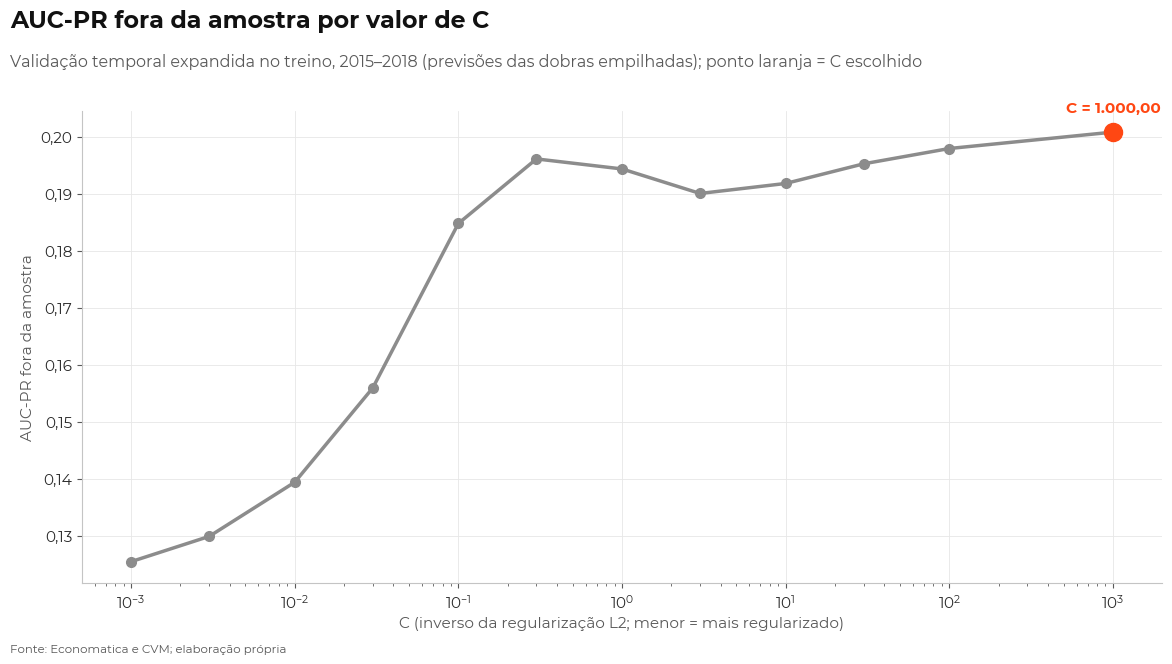

In [8]:
fig, ax = av.fig_selecao_c(tabC, res['C'])
style.titulos(fig, 'AUC-PR fora da amostra por valor de C',
              'Validação temporal expandida no treino, 2015–2018 (previsões das dobras empilhadas); ponto laranja = C escolhido')
style.salvar(fig, 'fig17_selecao_c')
plt.show()

**Leitura.** A AUC-PR fora da amostra sobe de 0,125 (C = 0,001, coeficientes muito encolhidos) para ~0,19–0,20 a partir de C ≈ 0,3 e fica **plana**: as diferenças entre C = 0,3 e C = 1.000 (0,196 contra 0,201) são bem menores que o erro-padrão (0,066). Ou seja, a regularização importa pouco, e a regra `'max'` escolhe C = 1.000, que é praticamente **sem penalização**. Com a grade antiga (até C = 10) o `C` escolhido era 0,3; as métricas do teste mudam um pouco entre as duas escolhas (por exemplo, AUC-ROC da logística 0,61 contra 0,67), mais um sinal de que, com 31 eventos, esse tipo de diferença é ruído. O aviso de borda só se aplica a C pequeno ou a grade curta; em C ≥ 100 estender a grade não muda nada. A AUC-PR está muito acima da taxa de eventos do treino (8,1%), então há sinal.

## 4. Modelos na validação (2019–2020)

Comparamos, ajustados no treino:
- **Z'' (baseline)**: o Z''-score de Altman para emergentes, recalibrado por uma logística de uma variável. A ordenação (AUC-PR e AUC-ROC) é a do próprio Z'';
- **Logística L2 com pesos de classe balanceados** (modelo principal): melhora o recall, mas **infla as probabilidades**;
- **Logística L2 sem pesos**: probabilidades calibradas, importantes para o Brier;
- **Logística com splines** em alavancagem e tamanho (o notebook 03 viu limiar na alavancagem e U no tamanho);
- **Gradient boosting raso** e **random forest** (desafiantes não lineares, hiperparâmetros fixos, sem tuning).

O **limiar** de cada modelo maximiza o F2 (privilegia o recall) nas previsões fora da amostra das dobras do treino. A validação **não** é usada para escolher nada.

> **Brier:** só compare entre modelos calibrados (Z'' e logística sem pesos). Com `class_weight='balanced'` as probabilidades saem infladas por construção, e o Brier piora sem que o ranking piore.

In [9]:
res_sp = mod.ajuste_completo(amostra, class_weight=None)
res_spl = mod.ajuste_completo(amostra, splines=True)
z = mod.ajuste_fixo(mod.pipeline_z, treino, dobras)
gb = mod.ajuste_fixo(mod.pipeline_gb, treino, dobras)
rf = mod.ajuste_fixo(mod.pipeline_rf, treino, dobras)

modelos = {"Z'' (baseline)": z,
           'Logística L2 (pesos balanceados)': res,
           'Logística L2 (sem pesos)': res_sp,
           'Logística com splines': res_spl,
           'Gradient boosting (desafiante)': gb,
           'Random forest (desafiante)': rf}
PRINCIPAL = 'Logística L2 (pesos balanceados)'
limiares = {k: v['limiar'] for k, v in modelos.items()}

prev_val = {k: mod.prever(v['modelo'], validacao) for k, v in modelos.items()}
av.tabela_metricas(validacao['Y'], prev_val, limiares)

,n,eventos,taxa,AUC-PR,AUC-ROC,Brier,recall top 20%,limiar,marcados,precisão,recall,F2
Z'' (baseline),286,11,"0,038","0,108","0,650","0,039","0,455","0,047",278,"0,040","1,000","0,171"
Logística L2 (pesos balanceados),286,11,"0,038","0,056","0,624","0,204","0,273","0,574",64,"0,047","0,273","0,139"
Logística L2 (sem pesos),286,11,"0,038","0,064","0,624","0,040","0,273","0,068",112,"0,062","0,636","0,224"
Logística com splines,286,11,"0,038","0,050","0,580","0,203","0,182","0,357",147,"0,054","0,727","0,209"
Gradient boosting (desafiante),286,11,"0,038","0,077","0,693","0,121","0,182","0,076",211,"0,052","1,000","0,216"
Random forest (desafiante),286,11,"0,038","0,148","0,681","0,113","0,364","0,480",34,"0,029","0,091","0,064"


**Leitura.** Na validação (11 eventos) **nenhuma logística supera o Z''** (AUC-PR 0,056 e 0,064, contra 0,108 do Z''), e os desafiantes ficam no meio. Com tão poucos eventos isso não é evidência contra a logística: a tabela serve só para detectar problemas (nenhum modelo pior que o acaso; o limiar do Z'' marca 97% da validação, pois foi escolhido em anos de taxa mais alta). A decisão sobre o modelo vem do teste, aberto uma única vez.

## 5. Inferência: as hipóteses H1–H4 (treino)

O estudo é de **associação**. Para testar as hipóteses ajustamos a logística **sem penalização** no treino, com **erro-padrão robusto agrupado por empresa** (o painel repete a mesma empresa em vários anos, então o erro-padrão comum seria otimista). Intervalos de 90%.

Como ler:
- razão de chances **por +1 desvio-padrão** da variável (winsorizada), controlando pelas demais e pelo setor;
- **confirma** = sinal esperado e p < 0,10. "Sinal certo, não significativo" **não** é confirmação;
- para a inferência usamos `regra='nenhuma'` (mediana) no sem-dívida: com uma constante mais a flag, o ajuste é o mesmo, mas só a mediana deixa o coeficiente de `sem_divida` legível ("sem dívida" contra uma empresa com dívida típica). Com o p99, a razão de chances da flag só desfaz o valor imputado e perde o sentido;
- coeficientes provavelmente **atenuados** pelo viés de sobrevivência (README).

In [10]:
Xi = mod.matriz_inferencia(treino)
coefs = mod.logit_agrupado(Xi, treino['Y'], treino['ticker'])
print(f"N = {coefs.attrs['N']} empresa-anos | {coefs.attrs['empresas']} empresas (clusters) | setor de referência: {Xi.attrs['setor_referencia']}")
hip = mod.tabela_hipoteses(coefs)
hip[['hipótese', 'sinal esperado', 'sinal estimado', 'odds_ratio', 'or_inf', 'or_sup', 'p', 'veredito']]

N = 1013 empresa-anos | 175 empresas (clusters) | setor de referência: Utilidade pública


,hipótese,sinal esperado,sinal estimado,odds_ratio,or_inf,or_sup,p,veredito
variável,,,,,,,,
alavancagem,H1,+,+,"1,392","1,037","1,869","0,064",confirma
divida_cp_share,H1,+,+,"1,357","1,013","1,818","0,086",confirma
roa,H2,−,−,"0,723","0,531","0,984","0,083",confirma
liquidez,H3,−,−,"0,849","0,610","1,183","0,418","sinal certo, não significativo"
fco_divida,H4,−,−,"0,286","0,103","0,791","0,043",confirma
log_ativo,controle,—,−,"0,752","0,567","0,997","0,097",controle


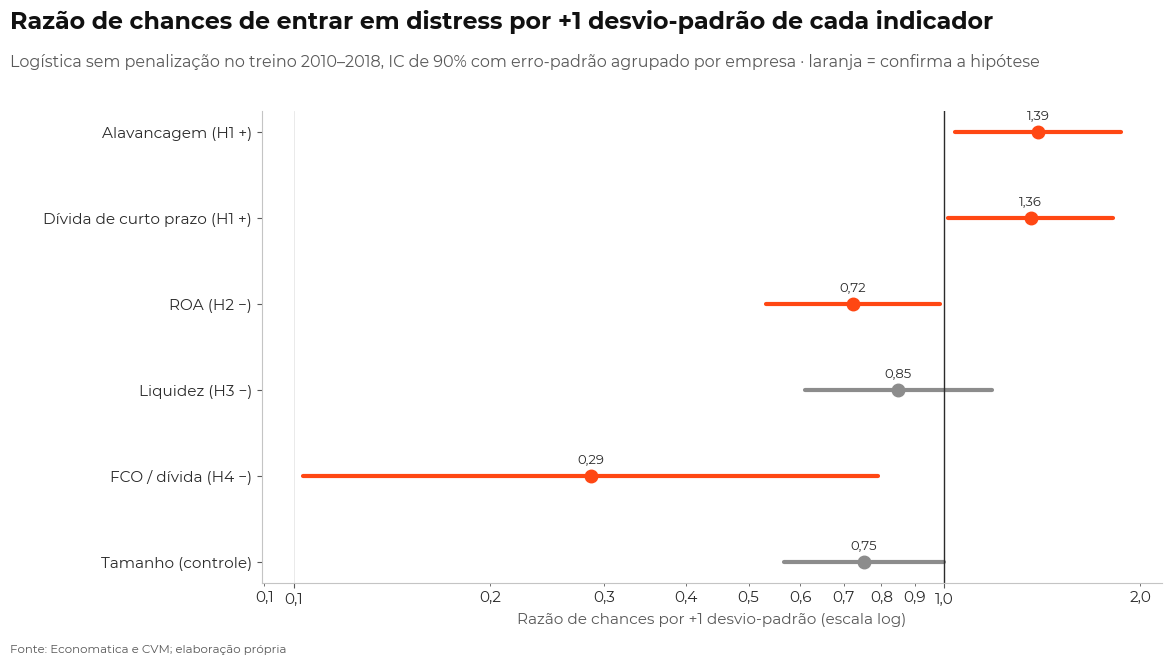

,coef,ep,z,p,odds_ratio,or_inf,or_sup
const,"-3,397","0,375","-9,050","0,000","0,033","0,018","0,062"
alavancagem,"0,331","0,179","1,849","0,064","1,392","1,037","1,869"
divida_cp_share,"0,305","0,178","1,717","0,086","1,357","1,013","1,818"
roa,"-0,325","0,187","-1,733","0,083","0,723","0,531","0,984"
liquidez,"-0,163","0,202","-0,811","0,418","0,849","0,610","1,183"
fco_divida,"-1,252","0,619","-2,023","0,043","0,286","0,103","0,791"
log_ativo,"-0,285","0,171","-1,662","0,097","0,752","0,567","0,997"
sem_divida,"1,341","0,670","2,002","0,045","3,823","1,271","11,505"
setor_Bens industriais,"0,251","0,473","0,531","0,595","1,285","0,591","2,796"
setor_Construção e imobiliário,"0,727","0,454","1,603","0,109","2,069","0,981","4,365"


In [11]:
fig, ax = av.fig_coeficientes(hip)
style.titulos(fig, 'Razão de chances de entrar em distress por +1 desvio-padrão de cada indicador',
              'Logística sem penalização no treino 2010–2018, IC de 90% com erro-padrão agrupado por empresa · laranja = confirma a hipótese')
fig.subplots_adjust(left=0.22)
style.salvar(fig, 'fig18_coeficientes')
plt.show()
coefs   # inclui constante, flag e dummies de setor

### Regressão de referência: modelo linear de probabilidade, resíduos e multicolinearidade

A logística acima é o modelo principal, mas o efeito dela vem em **razão de chances**, que é pouco intuitivo. O **modelo linear de probabilidade** (MQO sobre o 0/1, com o mesmo erro-padrão agrupado por empresa) dá o efeito em **pontos percentuais de probabilidade** por +1 desvio-padrão. Se as duas leituras contam a mesma história, a conclusão ganha força; se divergem, isso também é resultado.

Checagens: (i) **multicolinearidade** pelo VIF das contínuas; (ii) **resíduos**: no modelo linear, a proporção de probabilidades ajustadas fora de [0, 1]; nos dois modelos, o resíduo médio por faixa de valor ajustado (deve ficar perto de zero, dentro da banda de ±2 erros-padrão).

In [12]:
lpm = mod.mqo_agrupado(Xi, treino['Y'], treino['ticker'])
comp = pd.DataFrame({'razão de chances (logit)': coefs['odds_ratio'], 'p (logit)': coefs['p'],
                     'efeito em p.p. (linear)': lpm['p.p.'], 'IC 90% inf.': lpm['pp_inf'], 'IC 90% sup.': lpm['pp_sup'],
                     'p (linear)': lpm['p']}).drop('const')
aj = lpm.attrs['ajustados']
print(f"R² do modelo linear: {style.num_br(lpm.attrs['R2'], 3)} | ajustados < 0: {style.pct_br((aj < 0).mean(), 1)} "
      f"| ajustados > 1: {style.pct_br((aj > 1).mean(), 1)} | VIF máximo: {style.num_br(mod.vif_matriz(Xi).max(), 2)}")
comp

R² do modelo linear: 0,046 | ajustados < 0: 7,8% | ajustados > 1: 0,0% | VIF máximo: 1,99


,razão de chances (logit),p (logit),efeito em p.p. (linear),IC 90% inf.,IC 90% sup.,p (linear)
alavancagem,"1,392","0,064","2,976","0,557","5,395","0,043"
divida_cp_share,"1,357","0,086","2,228","0,117","4,339","0,082"
roa,"0,723","0,083","-2,582","-4,258","-0,907","0,011"
liquidez,"0,849","0,418","-0,835","-2,305","0,636","0,351"
fco_divida,"0,286","0,043","-0,635","-1,730","0,460","0,340"
log_ativo,"0,752","0,097","-2,467","-4,257","-0,678","0,023"
sem_divida,"3,823","0,045","10,205","1,500","18,910","0,054"
setor_Bens industriais,"1,285","0,595","0,602","-4,076","5,280","0,832"
setor_Construção e imobiliário,"2,069","0,109","5,676","0,229","11,123","0,087"
setor_Consumo cíclico,"1,638","0,306","2,511","-2,247","7,270","0,385"


In [13]:
mod.vif_matriz(Xi).to_frame()   # multicolinearidade na matriz do modelo (contínuas); acima de 5-10 seria preocupante

,VIF
alavancagem,"1,987"
divida_cp_share,"1,422"
roa,"1,383"
liquidez,"1,293"
fco_divida,"1,608"
log_ativo,"1,426"


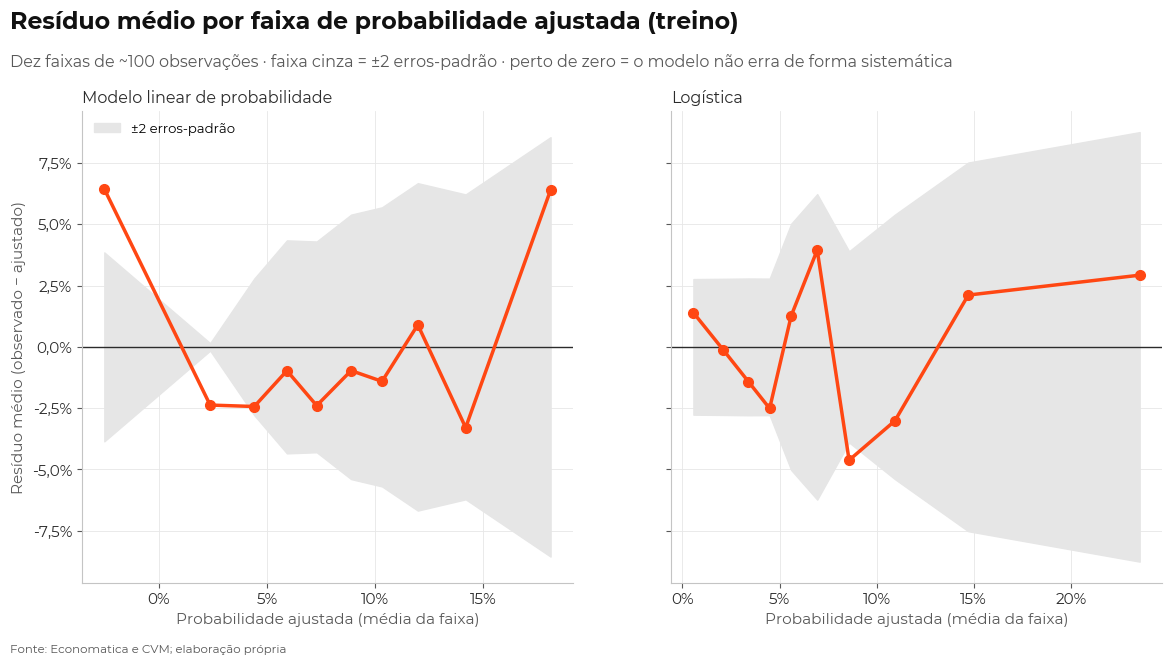

In [14]:
bl = mod.residuos_binados(treino['Y'], lpm.attrs['ajustados'])
bg = mod.residuos_binados(treino['Y'], mod.ajustados_logit(Xi, coefs))
fig, axs = av.fig_residuos(bl, bg)
style.titulos(fig, 'Resíduo médio por faixa de probabilidade ajustada (treino)',
              'Dez faixas de ~100 observações · faixa cinza = ±2 erros-padrão · perto de zero = o modelo não erra de forma sistemática')
style.salvar(fig, 'fig22_residuos')
plt.show()

**Leitura.** **Modelo linear de probabilidade** (efeito em pontos percentuais da probabilidade de distress, por +1 desvio-padrão; a taxa média no treino é 8,1%): alavancagem **+3,0 p.p.** (p = 0,043), dívida de curto prazo **+2,2 p.p.** (p = 0,082), ROA **−2,6 p.p.** (p = 0,011), tamanho **−2,5 p.p.** (p = 0,023), liquidez −0,8 p.p. (p = 0,35) e FCO/dívida −0,6 p.p. (p = 0,34).
- **Concordância com a logística:** H1 e H2 se confirmam nos dois modelos, com mesmo sinal e ordem de grandeza; H3 não se confirma em nenhum.
- **Divergência:** H4 (FCO/dívida) só aparece na logística. O efeito dessa variável não é linear (ela tem cauda longa), e o modelo linear não o captura. Tratamos H4 como **evidência mais fraca**, dependente da forma funcional.
- **Multicolinearidade:** VIF máximo de 1,99, bem abaixo de 5. Não há problema.
- **Resíduos:** o R² do modelo linear é baixo (4,6%), como se espera de um alvo raro, e 7,8% das probabilidades ajustadas ficam abaixo de zero (limitação conhecida do modelo linear para 0/1). No modelo linear, a faixa de menor valor ajustado (as probabilidades negativas) fica fora da banda de ±2 erros-padrão, com resíduo de +6 p.p.; na logística quase todas as faixas ficam dentro (uma, levemente fora), com leve subestimação do risco nas duas faixas mais altas. Por isso a logística é o modelo principal e o linear, a referência de leitura.

**Leitura.** **Logística (razões de chances por +1 desvio-padrão, intervalos de 90% agrupados por empresa):**
- **H1 (dívida eleva o risco): confirmada.** Alavancagem 1,39 (p = 0,064) e dívida de curto prazo 1,36 (p = 0,086). Em linguagem direta: uma empresa 1 desvio-padrão mais alavancada tem ~39% mais chance de entrar em distress, mantidas as demais. Os limites inferiores dos intervalos ficam perto de 1 (1,04 e 1,01), então o efeito é moderado e pouco preciso.
- **H2 (rentabilidade reduz o risco): confirmada.** ROA 0,72 (p = 0,083).
- **H3 (liquidez reduz o risco): não confirmada.** O sinal está certo (0,85), mas o efeito é indistinguível de zero (p = 0,42): controlada pelas demais (sobretudo o FCO/dívida), a liquidez não acrescenta.
- **H4 (geração de caixa reduz o risco): confirmada na logística**, o efeito mais forte (0,29, p = 0,043), com intervalo largo (0,10–0,79). Veja abaixo que ela **não** se confirma no modelo linear: depende da forma funcional.
- **Controles:** empresas maiores têm menos risco (0,75, p = 0,097); nenhum setor é significativo a 10%. A flag `sem_divida` (3,8, intervalo 1,3–11,5) vem de poucos eventos e **não** se sustenta fora da amostra (veja a importância por permutação e a robustez): não a interprete como efeito econômico.

Os p-valores ficam entre 0,04 e 0,10, então a confirmação vale como **associação com sinal esperado e evidência moderada**, e não como efeito preciso. Isso é associação, não causalidade.

## 6. Decisões pendentes: o que os dados dizem

Cada linha refaz **todo** o pipeline (escolha de C no treino incluída) com uma variante das decisões em aberto. A comparação é pela **AUC-PR fora da amostra no treino** (validação temporal), nunca pelo teste. Se as diferenças ficam dentro do erro-padrão, os dados não distinguem as opções: escolha a mais simples ou a mais defensável.

In [15]:
variantes = {
    'principal (p99 e 0 no sem-dívida, com setor, linear, pesos)': res,
    'sem-dívida: sem regra especial (mediana + flag)': mod.ajuste_completo(amostra, regra='nenhuma'),
    'sem controle de setor': mod.ajuste_completo(amostra, usar_setor=False),
    'com splines em alavancagem e tamanho': res_spl,
    'sem pesos de classe': res_sp,
}
linhas = []
for nome, r in variantes.items():
    t = r['tabela_C']
    e = t[t['escolhido']].iloc[0]
    linhas.append({'variante': nome, 'C': e['C'], 'AUC-PR (CV)': e['AUC-PR'], 'AUC-ROC (CV)': e['AUC-ROC'],
                   'Brier (CV)': e['Brier'], 'EP da AUC-PR': t.attrs['ep']})
pd.DataFrame(linhas).set_index('variante')

,C,AUC-PR (CV),AUC-ROC (CV),Brier (CV),EP da AUC-PR
variante,,,,,
"principal (p99 e 0 no sem-dívida, com setor, linear, pesos)","1.000,000","0,201","0,719","0,201","0,066"
sem-dívida: sem regra especial (mediana + flag),"0,300","0,211","0,736","0,202","0,070"
sem controle de setor,"1.000,000","0,204","0,713","0,202","0,064"
com splines em alavancagem e tamanho,"0,300","0,162","0,717","0,184","0,055"
sem pesos de classe,"1.000,000","0,171","0,712","0,059","0,052"


**Leitura.** Todas as variantes ficam a menos de um erro-padrão (0,066) da principal (AUC-PR 0,201), então **os dados não as distinguem**:
- **Regra do sem-dívida:** mediana + flag (0,211) contra p99/0 (0,201): empate; a mediana é mais simples e é a usada na inferência.
- **Setor provisório:** com (0,201) e sem (0,204) empatam; o setor não muda a previsão, então trocá-lo depois pelo Subsetor Bovespa não deve alterar as conclusões.
- **Splines:** pioram (0,162) e custam complexidade; ficamos com o modelo linear.
- **Pesos de classe:** sem pesos (0,171) fica abaixo, mas dentro do erro-padrão. Os pesos servem ao ranking e distorcem a probabilidade (o Brier sobe de 0,06 para 0,20).

### Regressão e machine learning contam a mesma história? Importância por permutação

Para comparar o que o ML "usa" com o que a regressão mostrou, medimos a **importância por permutação**, só com dados de treino: em cada dobra temporal o modelo é ajustado no passado, uma variável por vez é embaralhada na validação, e vemos **quanto a AUC-ROC cai**. Queda grande = o modelo depende da variável; perto de zero = ignora. Mesmo método para os três modelos, então as ordens são comparáveis. O teste não é usado.

In [16]:
fabricas = {'Logística L2 (pesos)': lambda: mod.pipeline_logit(res['C']),
            'Gradient boosting': mod.pipeline_gb,
            'Random forest': mod.pipeline_rf}
imp = {nome: mod.importancia_permutacao(f, treino, dobras, n_rep=10) for nome, f in fabricas.items()}
ordem = pd.DataFrame({n: t['queda AUC-ROC'].rank(ascending=False) for n, t in imp.items()})
ordem['|z| na logística sem penalização (posto)'] = coefs['z'].abs().rank(ascending=False).reindex(ordem.index)
pd.concat({'queda da AUC-ROC': pd.DataFrame({n: t['queda AUC-ROC'] for n, t in imp.items()}),
           'posto (1 = mais importante)': ordem}, axis=1).sort_values(('queda da AUC-ROC', 'Gradient boosting'), ascending=False)

queda da AUC-ROC                                 posto (1 = mais importante)                                                                         
                Logística L2 (pesos) Gradient boosting Random forest        Logística L2 (pesos) Gradient boosting Random forest |z| na logística sem penalização (posto)
variável                                                                                                                                                                 
fco_divida                     0,061             0,035         0,033                       1,000             1,000         1,000                                    2,000
divida_cp_share                0,041             0,028         0,029                       2,000             2,000         2,000                                    6,000
liquidez                       0,025             0,023         0,019                       4,000             3,000         5,000                                   11,000
setor                          0,018             0,012         0,003                       6,000             4,000         7,000                                      NaN
alavancagem                    0,020             0,011         0,022                       5,000             5,000         3,000                                    4,000
roa                            0,029             0,010         0,022                       3,000             6,000         4,000                                    5,000
log_ativo                      0,012             0,009         0,010                       7,000             7,000         6,000                                    7,000
sem_divida                    -0,018            -0,005        -0,008                       8,000             8,000         8,000                                    3,000

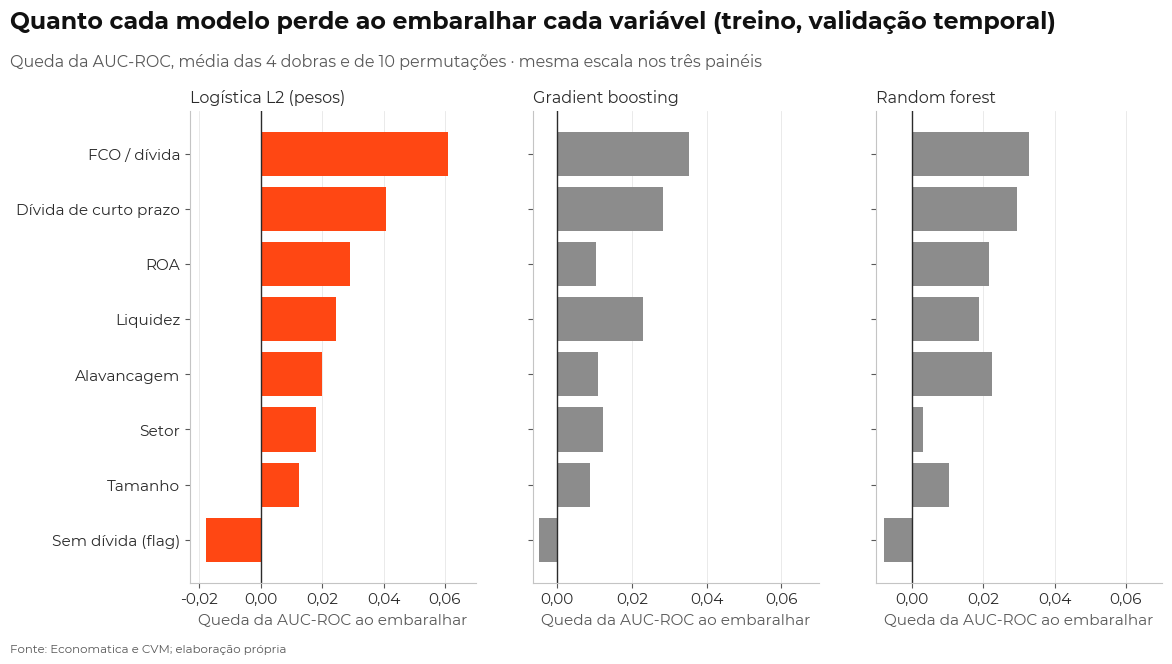

In [17]:
fig, axs = av.fig_importancia(imp, 'Logística L2 (pesos)')
style.titulos(fig, 'Quanto cada modelo perde ao embaralhar cada variável (treino, validação temporal)',
              'Queda da AUC-ROC, média das 4 dobras e de 10 permutações · mesma escala nos três painéis')
fig.subplots_adjust(left=0.16)
style.salvar(fig, 'fig23_importancia_permutacao')
plt.show()

**Leitura.** Os três modelos **concordam no topo**: FCO/dívida é a variável mais importante em todos e a dívida de curto prazo é a segunda em todos. Isso reforça a leitura da regressão (H4 e a parte de H1), e é mais forte que cada modelo sozinho. Há diferenças: o ROA é 3º na logística mas 6º no gradient boosting; a liquidez pesa mais no ML (3º) do que o coeficiente da logística sugere. A **flag `sem_divida` fica por último, com importância negativa nos três**: o efeito dela na inferência (OR 3,8) não ajuda a prever fora da amostra. Queda de AUC-ROC de 0,02 a 0,06 por variável é pequena em termos absolutos, e as médias vêm de 4 dobras com 10 a 20 eventos cada, então a **ordem** é indicativa, não precisa.

## 7. Teste (t = 2021–2023): abrir **uma vez**

Antes de rodar esta seção, o que está **congelado**: alvo (`cfg.ALVO_MODELO`), variáveis, regras de pré-processamento, `C` de cada logística (escolhido na seção 3) e limiar de cada modelo (previsões fora da amostra no treino). Se algo mudar depois de ver o teste, a avaliação deixa de ser independente: registre a mudança como análise exploratória.

O modelo é ajustado **só com o treino (2010–2018)**, e não com treino + validação. O motivo é o intervalo: o rótulo de t = 2019–2020 usa os anos 2021–2022, que são anos do teste. Treinar com eles seria usar o futuro do teste.

Intervalos de 90% por *bootstrap por empresa*; a pergunta central é se a logística supera a baseline Z'', então comparamos **diferenças** na mesma reamostragem.

In [18]:
teste = amostra[amostra['split'] == 'teste'].reset_index(drop=True)
prev_te = {k: mod.prever(v['modelo'], teste) for k, v in modelos.items()}
av.tabela_metricas(teste['Y'], prev_te, limiares)

,n,eventos,taxa,AUC-PR,AUC-ROC,Brier,recall top 20%,limiar,marcados,precisão,recall,F2
Z'' (baseline),546,31,"0,057","0,138","0,633","0,054","0,419","0,047",536,"0,056","0,968","0,227"
Logística L2 (pesos balanceados),546,31,"0,057","0,134","0,673","0,175","0,323","0,574",74,"0,108","0,258","0,202"
Logística L2 (sem pesos),546,31,"0,057","0,135","0,680","0,053","0,355","0,068",197,"0,096","0,613","0,296"
Logística com splines,546,31,"0,057","0,116","0,649","0,172","0,419","0,357",265,"0,083","0,710","0,283"
Gradient boosting (desafiante),546,31,"0,057","0,148","0,737","0,118","0,581","0,076",398,"0,068","0,871","0,259"
Random forest (desafiante),546,31,"0,057","0,149","0,756","0,106","0,548","0,480",68,"0,118","0,258","0,208"


**Contra a previsão ingênua.** O PDF pede comparar com a previsão de sempre a mesma taxa. Aqui, prever para toda empresa a **taxa de distress do treino**. Só vale para modelos de probabilidade calibrada (Z'' recalibrado e logística sem pesos; com pesos de classe o Brier não é comparável). Ganho = 1 − Brier / Brier ingênuo: positivo supera o ingênuo, zero empata.

In [19]:
b0 = av.brier_ingenuo(teste['Y'], treino['Y'].mean())
brier = av.tabela_metricas(teste['Y'], prev_te)['Brier'].astype(float)
calibrados = ["Z'' (baseline)", 'Logística L2 (sem pesos)']
print(f"Brier da previsão ingênua (taxa do treino = {style.pct_br(treino['Y'].mean(), 1)} para todas): {style.num_br(b0, 4)}")
pd.DataFrame({'Brier': brier[calibrados], 'ganho sobre o ingênuo': 1 - brier[calibrados] / b0})

Brier da previsão ingênua (taxa do treino = 8,1% para todas): 0,0541


,Brier,ganho sobre o ingênuo
Z'' (baseline),"0,054","0,007"
Logística L2 (sem pesos),"0,053","0,027"


In [20]:
p = prev_te[PRINCIPAL]
marcado = p >= limiares[PRINCIPAL]
cm = pd.crosstab(pd.Series(np.where(teste['Y'] == 1, 'entrou em distress', 'não entrou'), name='real'),
                 pd.Series(np.where(marcado, 'marcada como risco', 'não marcada'), name=f'{PRINCIPAL}, no limiar'))
cm

"Logística L2 (pesos balanceados), no limiar",marcada como risco,não marcada
real,,
entrou em distress,8,23
não entrou,66,449


In [21]:
resumo_boot, difs = av.bootstrap_empresas(teste['Y'], prev_te, teste['ticker'], referencia="Z'' (baseline)")
difs

,modelo,métrica,diferença mediana,ic_inf,ic_sup,P(> Z'' (baseline))
0,Logística L2 (pesos balanceados),AUC-PR,"-0,007","-0,098","0,068","0,447"
1,Logística L2 (pesos balanceados),AUC-ROC,"0,041","-0,075","0,167","0,706"
2,Logística L2 (sem pesos),AUC-PR,"-0,007","-0,100","0,067","0,449"
3,Logística L2 (sem pesos),AUC-ROC,"0,047","-0,071","0,171","0,732"
4,Logística com splines,AUC-PR,"-0,020","-0,105","0,047","0,325"
5,Logística com splines,AUC-ROC,"0,018","-0,098","0,131","0,600"
6,Gradient boosting (desafiante),AUC-PR,"0,011","-0,083","0,094","0,591"
7,Gradient boosting (desafiante),AUC-ROC,"0,106","0,004","0,206","0,952"
8,Random forest (desafiante),AUC-PR,"0,015","-0,082","0,103","0,611"
9,Random forest (desafiante),AUC-ROC,"0,121","0,023","0,227","0,977"


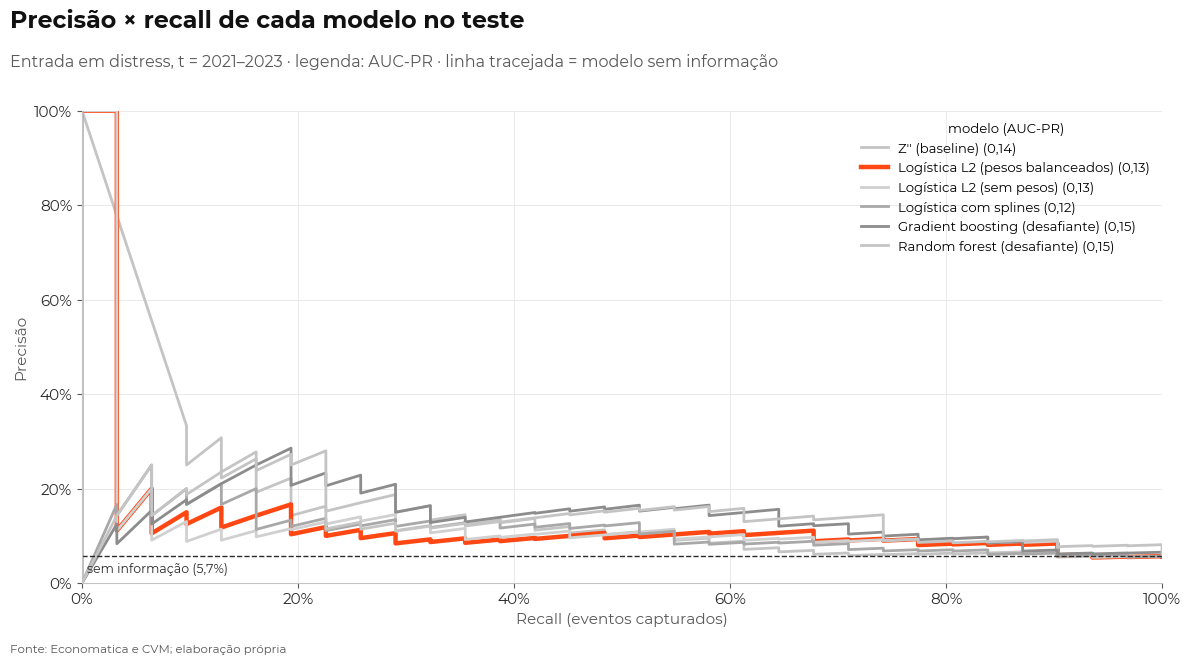

In [22]:
fig, ax = av.fig_pr(teste['Y'], prev_te, PRINCIPAL)
style.titulos(fig, 'Precisão × recall de cada modelo no teste',
              'Entrada em distress, t = 2021–2023 · legenda: AUC-PR · linha tracejada = modelo sem informação')
style.salvar(fig, 'fig19_precisao_recall_teste')
plt.show()

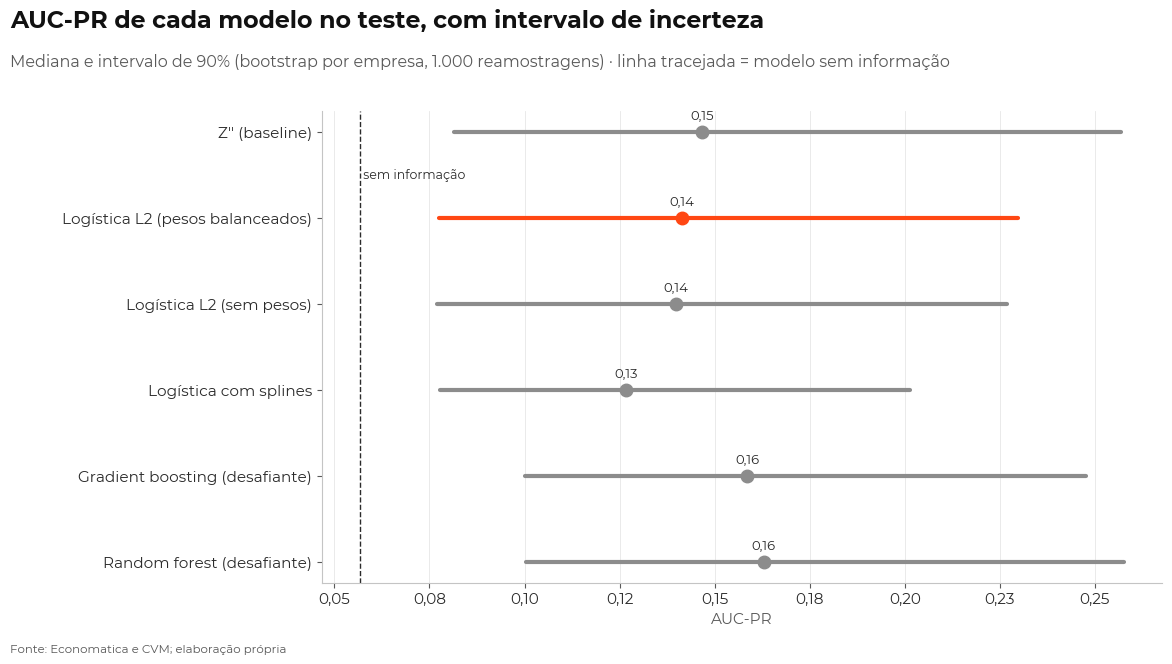

,modelo,métrica,mediana,ic_inf,ic_sup
0,Z'' (baseline),AUC-PR,"0,147","0,082","0,257"
1,Z'' (baseline),AUC-ROC,"0,636","0,531","0,729"
2,Logística L2 (pesos balanceados),AUC-PR,"0,141","0,077","0,230"
3,Logística L2 (pesos balanceados),AUC-ROC,"0,677","0,589","0,754"
4,Logística L2 (sem pesos),AUC-PR,"0,140","0,077","0,227"
5,Logística L2 (sem pesos),AUC-ROC,"0,684","0,598","0,759"
6,Logística com splines,AUC-PR,"0,127","0,078","0,202"
7,Logística com splines,AUC-ROC,"0,652","0,549","0,736"
8,Gradient boosting (desafiante),AUC-PR,"0,159","0,100","0,248"
9,Gradient boosting (desafiante),AUC-ROC,"0,738","0,661","0,814"


In [23]:
fig, ax = av.fig_ic(resumo_boot, 'AUC-PR', destaque=PRINCIPAL, taxa=teste['Y'].mean())
style.titulos(fig, 'AUC-PR de cada modelo no teste, com intervalo de incerteza',
              'Mediana e intervalo de 90% (bootstrap por empresa, 1.000 reamostragens) · linha tracejada = modelo sem informação')
fig.subplots_adjust(left=0.27)
style.salvar(fig, 'fig20_auc_pr_ic_teste')
plt.show()
resumo_boot

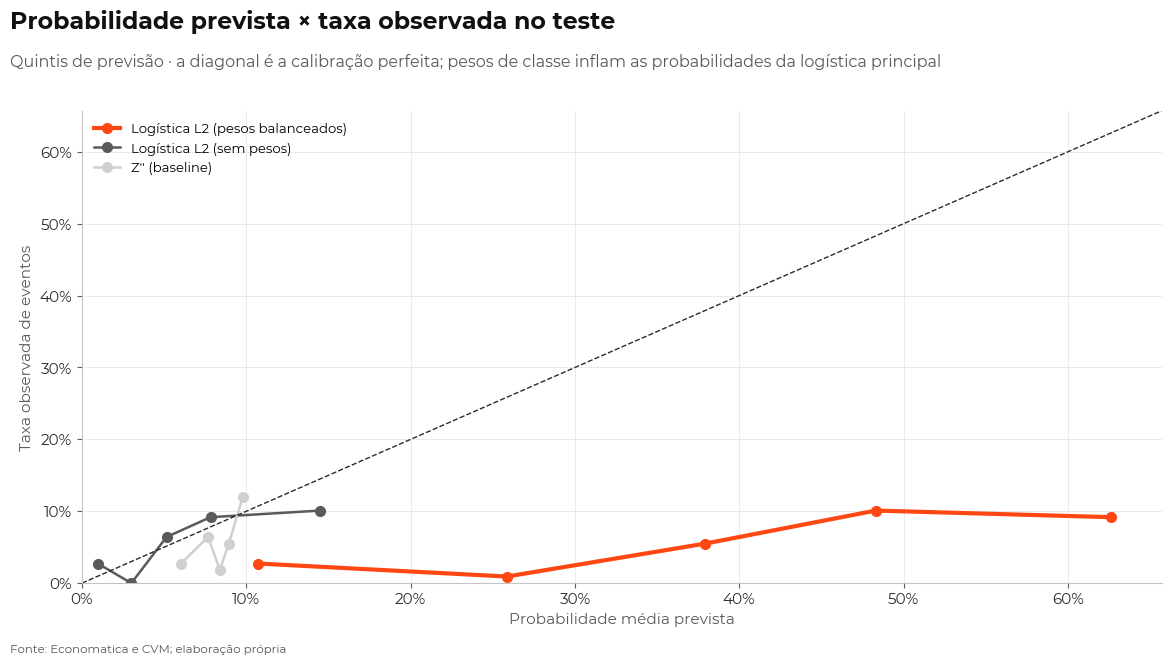

In [24]:
fig, ax = av.fig_calibracao(teste['Y'], {k: prev_te[k] for k in [PRINCIPAL, 'Logística L2 (sem pesos)', "Z'' (baseline)"]}, PRINCIPAL)
style.titulos(fig, 'Probabilidade prevista × taxa observada no teste',
              'Quintis de previsão · a diagonal é a calibração perfeita; pesos de classe inflam as probabilidades da logística principal')
style.salvar(fig, 'fig21_calibracao_teste')
plt.show()

In [25]:
# Previsões do teste para consulta (data/processed não é versionado)
saida = teste[['ticker', 'ano', 'Y']].copy()
for k, v in prev_te.items():
    saida[k] = v
saida.to_csv(cfg.DATA_PROCESSED / 'previsoes_teste.csv', index=False)
saida.sort_values(PRINCIPAL, ascending=False).head(15)

,ticker,ano,Y,Z'' (baseline),Logística L2 (pesos balanceados),Logística L2 (sem pesos),Logística com splines,Gradient boosting (desafiante),Random forest (desafiante)
215,FRIO3,2021,1,"0,108","0,851","0,376","0,814","0,769","0,599"
333,MTSA4,2021,0,"0,056","0,813","0,287","0,529","0,392","0,384"
330,MTRE3,2021,0,"0,067","0,812","0,317","0,801","0,557","0,522"
62,CALI3,2022,0,"0,089","0,777","0,259","0,877","0,832","0,690"
319,MGEL4,2023,0,"0,088","0,773","0,215","0,737","0,564","0,455"
61,CALI3,2021,0,"0,086","0,765","0,250","0,857","0,736","0,600"
79,CEDO4,2021,0,"0,106","0,759","0,237","0,779","0,705","0,618"
331,MTRE3,2022,0,"0,074","0,749","0,239","0,717","0,521","0,493"
56,BOBR4,2022,0,"0,108","0,736","0,222","0,816","0,704","0,671"
21,AMAR3,2021,1,"0,097","0,731","0,219","0,735","0,740","0,657"


**Leitura.** (i) **Previsão.** A AUC-PR da logística (0,134) é ~2,4 vezes a taxa de eventos (0,057), mas **igual à do Z'' (0,138)**: a diferença é −0,007, com intervalo de −0,10 a +0,07 (P(logística > Z'') = 0,45). Na AUC-ROC a logística fica na frente (0,673 contra 0,633), mas o intervalo da diferença (−0,08 a +0,17) inclui zero. **Empate técnico.** (ii) **Incerteza.** Com 31 eventos, o intervalo de 90% da AUC-PR vai de ~0,08 a ~0,25 para todos os modelos: o teste não consegue distinguir diferenças de até ~0,07. (iii) **ML.** Gradient boosting e random forest ficam na frente na AUC-ROC (0,74 e 0,76 contra 0,63 do Z''); a diferença é significativa a 90% (+0,11 e +0,12, intervalos 0,01–0,21 e 0,02–0,23), mas **não** na AUC-PR (+0,02 e +0,01, P ≈ 0,6). Com 10 comparações, um ou dois intervalos que excluem zero era o esperado por acaso; trate como pista de não linearidade, não como resultado. (iv) **Limiar.** A logística principal marca 74 de 546 empresas: capta 8 dos 31 eventos (recall 26%) com 66 alarmes falsos (precisão 11%, cerca do dobro da taxa-base). O Z'' marca 536 de 546 (98%): o limiar, escolhido em anos de taxa mais alta, vira "todo mundo é risco", e a precisão de 5,6% é a do acaso. Limiar fixo entre períodos é frágil; uma regra por ranking (os k% mais arriscados) é mais robusta: no top 20%, Z'' capta 42% dos eventos, a logística 32%, o gradient boosting 55% e o random forest 58% (acaso: 20%). (v) **Calibração e Brier.** Os pesos de classe inflam a probabilidade da logística principal (previsão média de 16% a 63% contra 2% a 9% observados): use-a só como **ranking**. A logística sem pesos fica perto da diagonal, mas numa faixa curta. Contra a previsão ingênua (sempre a taxa do treino, Brier 0,0541), o Z'' ganha 0,7% e a logística sem pesos 2,7%: **em probabilidade absoluta, os modelos praticamente empatam com o ingênuo**; o ganho está em ordenar as empresas.

## 8. Robustez

Cada linha refaz o pipeline inteiro (escolha de C no treino, ajuste no treino, avaliação no teste) para uma amostra ou especificação alternativa. O que importa é se a **conclusão** (logística contra Z'') se mantém, e não o número exato. Do notebook 03 ainda falta o **painel balanceado**: depende de a dupla definir o que é balanceado aqui.

In [26]:
rob = [mod.avaliar_cenario(amostra, f'principal (alvo {cfg.ALVO_MODELO})'),
       mod.avaliar_cenario(mod.preparar_amostra(ea, cfg.ALVO_ROBUSTEZ),
                           f'alvo {cfg.ALVO_ROBUSTEZ} ({cfg.DEFINICOES_ALVO[cfg.ALVO_ROBUSTEZ][0].upper()})'),
       mod.avaliar_cenario(amostra[~amostra['sem_divida']], 'sem as empresas sem dívida'),
       mod.avaliar_cenario(amostra, 'sem controle de setor', usar_setor=False)]
pd.DataFrame(rob).set_index('cenário')

,n treino,eventos treino,n teste,eventos teste,C,AUC-PR logística,AUC-PR Z'',AUC-ROC logística,AUC-ROC Z'',sem informação (AUC-PR)
cenário,,,,,,,,,,
principal (alvo B),1013,82,546,31,"1.000,000","0,134","0,138","0,673","0,633","0,057"
alvo A (EBIT),872,115,470,52,"1,000","0,189","0,168","0,600","0,639","0,111"
sem as empresas sem dívida,976,77,540,31,"1,000","0,144","0,133","0,693","0,629","0,057"
sem controle de setor,1013,82,546,31,"1.000,000","0,139","0,138","0,675","0,633","0,057"


**Leitura.** A logística ganha do Z'' na AUC-PR em três dos quatro cenários (por pouco, 0,00 a 0,02) e na AUC-ROC também em três; no **alvo A (EBIT)** ela ganha na AUC-PR (0,189 contra 0,168; taxa-base 0,111, 52 eventos) mas perde na AUC-ROC (0,600 contra 0,639). Retirar as empresas sem dívida eleva um pouco a logística (AUC-ROC 0,693), compatível com a fragilidade da flag. Remover o controle de setor não muda nada (0,139; 0,675). **A conclusão se mantém em todos os cenários**: a logística não é claramente melhor nem pior que o Z''. Com o alvo A o resultado muda de sinal entre as métricas, então a conclusão **depende da definição do alvo**, e isso entra nas limitações.

## 9. Conclusões

**1. Hipóteses (seção 5, associação, não causalidade).** Indicadores contábeis estão associados à entrada em distress nos dois anos seguintes, no sentido esperado: **H1** (alavancagem e dívida de curto prazo: +), **H2** (ROA: −) e **H4** (FCO/dívida: −) se confirmam na logística com evidência moderada (p entre 0,04 e 0,09); **H3** (liquidez) não. H1 e H2 também se confirmam no modelo linear de probabilidade (+3,0 p.p. por desvio-padrão de alavancagem; −2,6 p.p. por desvio-padrão de ROA); H4 só aparece na logística. Empresas maiores têm menos risco.

**2. Regressão e machine learning contam a mesma história no essencial.** A importância por permutação põe FCO/dívida e dívida de curto prazo no topo nos três modelos; divergem na ordem do ROA e da liquidez.

**3. Previsão (seção 7).** Em 2021–2023 (31 eventos), a logística tem AUC-PR de 0,13 e AUC-ROC de 0,67, bem acima do acaso (0,057 e 0,5), mas **empata com o Z'' recalibrado** (diferença de AUC-PR de −0,007, intervalo de −0,10 a +0,07). As árvores (gradient boosting e random forest) têm AUC-ROC maior (0,74–0,76), o que sugere não linearidade, mas não superam o Z'' na AUC-PR. Em probabilidade absoluta, nenhum modelo supera de forma relevante a previsão ingênua (ganho de Brier de até 2,7%). Os indicadores ajudam a **ordenar** empresas por risco, não a estimar a probabilidade.

**4. Uso prático.** Com o limiar escolhido, a logística marca 74 de 546 empresas, capta 26% dos distress (8 de 31) e erra 66 alarmes (precisão de 11%, o dobro da taxa-base). O limiar do Z'' marca quase todas as empresas. Uma regra "os 20% mais arriscados" capta de 32% (logística) a 58% (random forest) dos eventos, contra 20% do acaso.

**5. Limitações.**
- **Poucos eventos** (82, 11 e 31): intervalos largos; o teste não distingue diferenças de ~0,07 de AUC-PR, e escolhas como o `C` mudam as métricas de forma comparável ao ruído.
- **Viés de sobrevivência:** nenhuma das 469 empresas que cancelaram o registro está na base; as probabilidades são risco relativo.
- **Alvo** baseado em EBITDA e **despesa financeira bruta** do Economatica (câmbio contamina a despesa); com o alvo A (EBIT) o resultado muda entre métricas.
- **Setor provisório** (macrossetor da CVM) e **sem controle de tempo** (juros, Selic): a taxa de eventos varia entre os períodos (8,1%, 3,8%, 5,7%) e desloca o limiar.
- **Flag `sem_divida`:** estimada com poucos eventos e sem ganho fora da amostra.
- Hiperparâmetros das árvores fixos (sem tuning), de propósito; a comparação com o ML é indicativa.
- Variáveis que ficaram de fora: governança, estrutura de capital detalhada, cronograma da dívida, exposição cambial (H5 abandonada por falta de dado).

### Decisões que continuam com a dupla
- **Alvo A ou B** (`cfg.ALVO_MODELO`; hoje B).
- **Regra do sem-dívida** (seção 6; os dados não distinguem as opções).
- **Controle de tempo:** nenhum, ou Selic/PIB (`data/raw/macro/macro_anual.csv` e `cfg.MACRO_COLS`).
- **Beta do limiar** (`cfg.BETA_LIMIAR`, hoje 2): quanto vale um distress não detectado contra um alarme falso?
- **Painel balanceado** na robustez.
- **Tuning** das árvores (por exemplo, XGBoost, já no `requirements.txt`), com dados e validação que o permitam.